In [1]:
pip install wfdb scipy scikit-learn pandas numpy matplotlib joblib

In [2]:
# ============================================
# Imports
# ============================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm

from google.colab import drive

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix,
    classification_report
)

import joblib

# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
CSV_PATH = "//content/drive/MyDrive/ML_MODEL/ecg_features.csv"

df = pd.read_csv(CSV_PATH)

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (1784, 221)


,RR_Mean,RR_Median,RR_STD,RR_Min,RR_Max,HR_Mean,HR_Median,HR_STD,HR_Min,HR_Max,...,Record,HRV_DFA_alpha2,HRV_MFDFA_alpha2_Width,HRV_MFDFA_alpha2_Peak,HRV_MFDFA_alpha2_Mean,HRV_MFDFA_alpha2_Max,HRV_MFDFA_alpha2_Delta,HRV_MFDFA_alpha2_Asymmetry,HRV_MFDFA_alpha2_Fluctuation,HRV_MFDFA_alpha2_Increment
0,547.225806,546.0,6.003814,538.0,558.0,109.657135,109.890110,1.201656,107.526882,111.524164,...,P00001_E01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,508.421053,508.0,1.438169,506.0,512.0,118.013365,118.110236,0.333349,117.187500,118.577075,...,P00016_E01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,595.755102,596.0,3.371735,590.0,604.0,100.715743,100.671141,0.568767,99.337748,101.694915,...,P00017_E01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,583.351351,578.0,39.862070,524.0,688.0,103.318765,103.806228,6.822742,87.209302,114.503817,...,P00032_E01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,405.694444,406.0,2.880195,400.0,412.0,147.902020,147.783251,1.051238,145.631068,150.000000,...,P00032_E02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Remove label and metadata
X = df.drop(columns=["Label", "Record"], errors="ignore")
y = df["Label"]

# Keep only numeric columns
X = X.select_dtypes(include=["number"])

# Remove columns that are entirely NaN
X = X.dropna(axis=1, how="all")

# Replace infinities
X = X.replace([np.inf, -np.inf], np.nan)

# Fill remaining NaNs
X = X.fillna(X.median(numeric_only=True))

print("Remaining NaNs:", X.isna().sum().sum())
print("Remaining inf:", np.isinf(X.values).sum())

Remaining NaNs: 0
Remaining inf: 0


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(1427, 211)
(357, 211)


In [6]:
# Calculate class imbalance ratio
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("Negative samples:", negative)
print("Positive samples:", positive)
print("scale_pos_weight:", scale_pos_weight)

Negative samples: 792
Positive samples: 635
scale_pos_weight: 1.247244094488189


In [7]:
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

rfecv = RFECV(
    estimator=xgb,
    step=10,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=2
)

rfecv.fit(X_train, y_train)

selected_features = X_train.columns[rfecv.support_]

print("Number of selected features:", len(selected_features))
print(selected_features.tolist())

X_train = rfecv.transform(X_train)
X_test = rfecv.transform(X_test)

Fitting estimator with 211 features.
Fitting estimator with 201 features.
Fitting estimator with 191 features.
Fitting estimator with 181 features.
Fitting estimator with 171 features.
Fitting estimator with 161 features.
Fitting estimator with 151 features.
Fitting estimator with 141 features.
Fitting estimator with 131 features.
Fitting estimator with 121 features.
Number of selected features: 111
['RR_Mean', 'RR_Min', 'RR_Max', 'HR_STD', 'HR_Min', 'PR_Median', 'PR_STD', 'PR_Min', 'PR_Max', 'QRS_Mean', 'QRS_Median', 'QRS_STD', 'QT_Mean', 'QT_Median', 'QT_Min', 'QT_Max', 'QTc_Mean', 'QTc_Median', 'QTc_STD', 'QTc_Min', 'QTc_Max', 'P_Amp_Mean', 'Q_Amp_Mean', 'Q_Amp_STD', 'R_Amp_STD', 'S_Amp_Mean', 'S_Amp_STD', 'T_Amp_Mean', 'T_Amp_STD', 'RS_Ratio_Mean', 'RS_Ratio_STD', 'RQ_Ratio_Mean', 'RQ_Ratio_STD', 'QRS_Energy_STD', 'T_Area_Mean', 'T_Energy_Mean', 'T_Energy_STD', 'ST_Level_Mean', 'R_Slope_Mean', 'T_Slope_Mean', 'P_Duration_Mean', 'P_Duration_STD', 'T_Duration_Mean', 'T_Duration_STD',

In [8]:
model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=None,
              num_parallel_tree=None, ...)

In [9]:
# Probability of CHD
y_prob = model.predict_proba(X_test)[:, 1]

threshold = 0.26

y_pred = (y_prob >= threshold).astype(int)

In [10]:
print("="*60)
print("CLASSIFICATION REPORT")
print("="*60)

print(classification_report(y_test, y_pred))

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC AUC  :", roc_auc_score(y_test, y_prob))

print("\nConfusion Matrix")

cm = confusion_matrix(y_test, y_pred)

print(cm)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.77      0.61      0.68       198
           1       0.61      0.78      0.69       159

    accuracy                           0.68       357
   macro avg       0.69      0.69      0.68       357
weighted avg       0.70      0.68      0.68       357

Accuracy : 0.6834733893557423
Precision: 0.6138613861386139
Recall   : 0.779874213836478
F1 Score : 0.6869806094182825
ROC AUC  : 0.7556699066133028

Confusion Matrix
[[120  78]
 [ 35 124]]


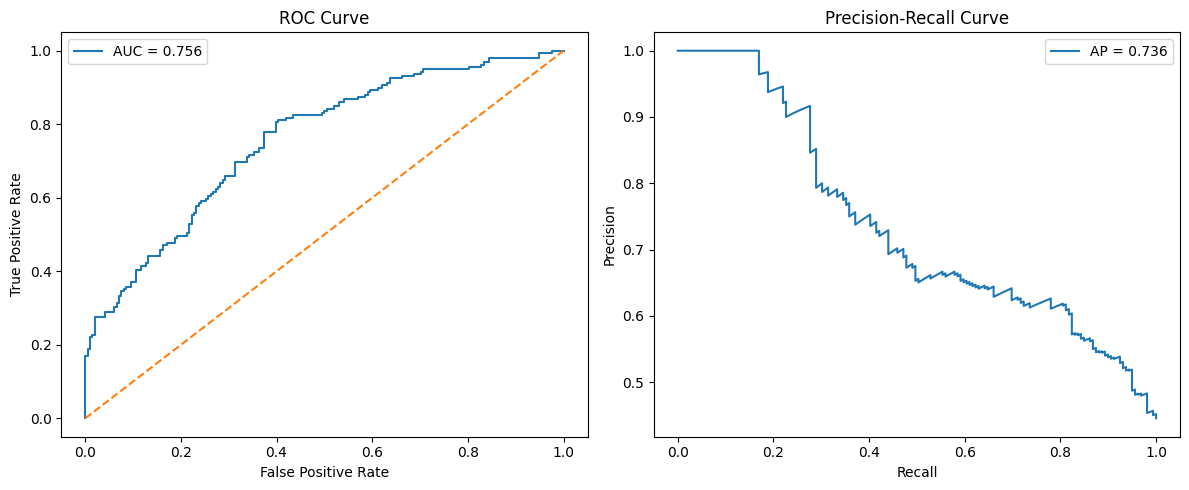

In [11]:
roc_fpr, roc_tpr, _ = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

precision, recall, _ = precision_recall_curve(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(roc_fpr, roc_tpr,
         label=f"AUC = {roc_auc:.3f}")

plt.plot([0,1],[0,1],'--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.subplot(1,2,2)

plt.plot(recall, precision,
         label=f"AP = {pr_auc:.3f}")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
print(len(X.columns))
print(len(model.feature_importances_))
print(rfecv.n_features_)
print(type(X_train))

211
111
111
<class 'numpy.ndarray'>


             Feature  Importance
17        QTc_Median    0.025508
3             HR_STD    0.024885
23         Q_Amp_STD    0.020359
30      RS_Ratio_STD    0.017372
13         QT_Median    0.015307
57           HRV_PIP    0.012737
38      R_Slope_Mean    0.012361
51         HRV_pNN20    0.012335
4             HR_Min    0.011982
16          QTc_Mean    0.011438
88            L1_Min    0.011371
46          HRV_CVSD    0.011340
12           QT_Mean    0.011327
34       T_Area_Mean    0.011301
22        Q_Amp_Mean    0.011278
56  HRV_CSI_Modified    0.011164
31     RQ_Ratio_Mean    0.011095
25        S_Amp_Mean    0.010979
10        QRS_Median    0.010941
58          HRV_IALS    0.010707


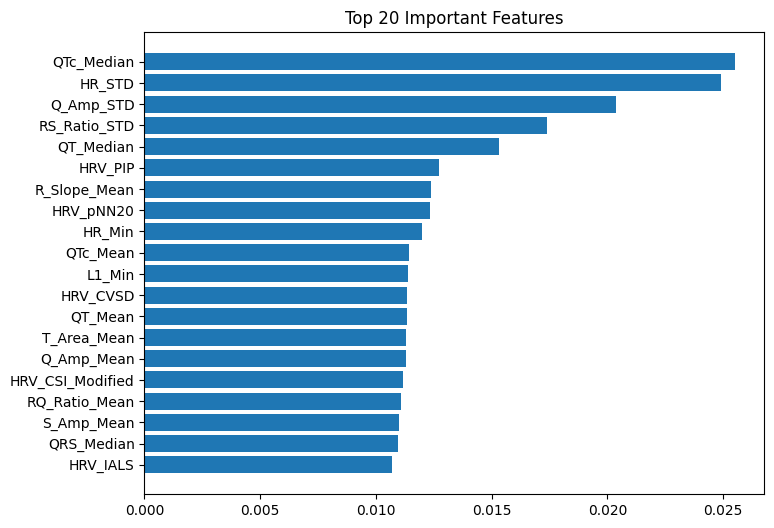

In [13]:
importance = pd.DataFrame({
    "Feature": selected_features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance.head(20)

print(importance.head(20))

plt.figure(figsize=(8,6))

plt.barh(
    importance["Feature"][:20],
    importance["Importance"][:20]
)

plt.gca().invert_yaxis()

plt.title("Top 20 Important Features")

plt.show()

In [14]:
joblib.dump(model, "trained_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [15]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.1, 0.91, 0.05)

results = []

for t in thresholds:
    y_pred = (y_prob >= t).astype(int)

    results.append({
        "Threshold": t,
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "Accuracy": accuracy_score(y_test, y_pred)
    })

results = pd.DataFrame(results)

print(results)

    Threshold  Precision    Recall        F1  Accuracy
0        0.10   0.519031  0.943396  0.669643  0.585434
1        0.15   0.549407  0.874214  0.674757  0.624650
2        0.20   0.573913  0.830189  0.678663  0.649860
3        0.25   0.614634  0.792453  0.692308  0.686275
4        0.30   0.619048  0.735849  0.672414  0.680672
5        0.35   0.633136  0.672956  0.652439  0.680672
6        0.40   0.644737  0.616352  0.630225  0.677871
7        0.45   0.659259  0.559748  0.605442  0.675070
8        0.50   0.650407  0.503145  0.567376  0.658263
9        0.55   0.698113  0.465409  0.558491  0.672269
10       0.60   0.721649  0.440252  0.546875  0.675070
11       0.65   0.741573  0.415094  0.532258  0.675070
12       0.70   0.740741  0.377358  0.500000  0.663866
13       0.75   0.760000  0.358491  0.487179  0.663866
14       0.80   0.790323  0.308176  0.443439  0.655462
15       0.85   0.846154  0.276730  0.417062  0.655462
16       0.90   0.902439  0.232704  0.370000  0.647059


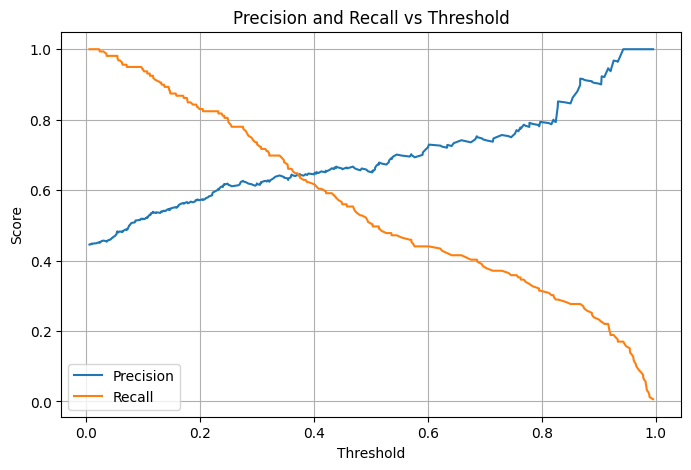

Best Threshold: 0.24294564
Best F1: 0.7010869564726622


In [16]:
from sklearn.metrics import precision_recall_curve
import numpy as np

precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

f1_scores = 2 * (precision[:-1] * recall[:-1]) / (
    precision[:-1] + recall[:-1] + 1e-10
)

best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]


plt.figure(figsize=(8,5))
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs Threshold")
plt.legend()
plt.grid(True)

plt.show()

print("Best Threshold:", best_threshold)
print("Best F1:", f1_scores[best_index])